# 3.01 · Surrogates 101: a cheap stand-in for the forward model

*Topic 3 is under development: content and numbering may still change.*

**Before this:** [2.06](2-06_matrix_primer.ipynb) (SVD), [2.10](2-10_loss_functions_optimisation.ipynb) (loss functions, Adam), [2.12](2-12_gaussian_processes.ipynb) (Gaussian processes), [2.13](2-13_model_errors_cd_cp.ipynb) (model error $\mathbf C_p$) ·
**You will be able to:** plan where to run an expensive model; compress its outputs; compare surrogates by
learning curves in units of the data noise; carry the surrogate's error into the likelihood and check coverage ·
**Optional sections:** the design study in section 3 and the worked example at the end of section 6 can be skimmed.

Every sampler in this tutorial calls the forward model again and again: thousands of times for NUTS, tens of
thousands for SMC, once per member and iteration for EnKI. When one run takes minutes or hours (3-D viscoelastic
relaxation, dynamic rupture, tsunami propagation), those calls are the whole cost of the inversion. A **surrogate**
is a fast function fitted to a limited number of forward runs; it then stands in for the model inside the inversion.
This notebook builds surrogates of the afterslip black box, measures their errors in units of the GPS noise, and
shows that a surrogate error is a model error: left out of the likelihood, it makes the posterior overconfident.

**Words this notebook defines:** surrogate (emulator), training run, design of experiments, random design, Latin
hypercube, Sobol sequence, space filling, output compression (PCA), test set (held-out runs), learning curve,
interpolation and extrapolation, surrogate error, $\mathbf C_p$ from validation residuals, coverage.

**Problems in this notebook**

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| single-patch afterslip (`bayeskit.afterslip`) | θ = (log aσ, log v0, Δτ): 3 | surface displacement at 40 GPS epochs, day 1 to year 1 (log spaced) | ODE $v = 2v_0\sinh(\tau/a\sigma)$, $d\tau/dt = -k v$, solved by diffrax (implicit Kvaerno5) | no: slip grows like $a\sigma\log(1+t/t_c)$ with $t_c \propto e^{-\Delta\tau/a\sigma}$ |
| coverage test (section 7) | 2: log aσ, log v0 (Δτ known) | same 40 epochs | the ODE, or a surrogate of it | no |

Prior: uniform box, aσ 0.2-2 MPa, v0 0.001-1 m/yr, Δτ 1-5 MPa. GPS noise σ = 2 mm, independent between epochs.
Forward runs: the cached sets of `bayeskit.afterslip` (4,000 uniform random draws, split into 3,200 training,
400 validation and 400 test runs; and 4,000 Latin-hypercube draws), plus a few hundred new runs in section 3.
Three roles, kept apart: **training** runs are what a surrogate is fitted to (each surrogate also builds its output
compression from its own training runs only); **validation** runs choose settings (the number of output modes K)
and estimate the surrogate error; **test** runs only grade, and in section 7 they supply the true values of the
synthetic repeats. Nothing is fitted or tuned on the test runs.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt
import bayeskit as bk
from bayeskit import problems as P, samplers as SM, diagnostics as D, plotting as BP, style as S
import time
import jax
import jax.numpy as jnp
from scipy.optimize import minimize
from scipy.stats import qmc
from sklearn.neighbors import KNeighborsRegressor
from bayeskit import afterslip as A

T0 = time.time()
SIG = 2.0                                           # GPS noise (mm)
T_OBS = A.T_OBS
LO, HI = A.SP_BOUNDS[:, 0], A.SP_BOUNDS[:, 1]
NAMES = ["log aσ", "log v0", "Δτ (MPa)"]
th_all, u_all = A.training_set_single(4000, seed=0)            # uniform random design, cached
th_lhs, u_lhs = A.training_set_single(4000, seed=0, design="lhs")
U_all = 1000.0 * u_all                                          # mm
X_all = (th_all - LO) / (HI - LO)                               # inputs scaled to the unit cube
TR, VA, TE = np.arange(0, 3200), np.arange(3200, 3600), np.arange(3600, 4000)
Xte, Ute = X_all[TE], U_all[TE]
true_batch = jax.jit(jax.vmap(lambda th: 1000.0 * A.single_patch_series(th, T_OBS)))   # the expensive model (mm)


def to_theta(x):
    return LO + np.asarray(x) * (HI - LO)


def run_true(X):
    """True forward model at scaled inputs X (m, 3), in batches of 256 (mm)."""
    X = np.atleast_2d(X)
    return np.concatenate([np.asarray(true_batch(jnp.asarray(to_theta(X[i:i + 256])))) for i in range(0, len(X), 256)])


def rms_err(pred, ref=Ute):
    """RMS error over the 40 epochs at every test point (mm)."""
    return np.sqrt(((pred - ref) ** 2).mean(1))


print(f"training runs {len(TR)}, validation {len(VA)}, test {len(TE)}; outputs per run {U_all.shape[1]} epochs")
print(f"displacement at year 1 over the prior: {U_all[:, -1].min():.1f} to {U_all[:, -1].max():.0f} mm "
      f"(median {np.median(U_all[:, -1]):.0f} mm); noise sigma {SIG} mm")

training runs 3200, validation 400, test 400; outputs per run 40 epochs
displacement at year 1 over the prior: 0.7 to 995 mm (median 324 mm); noise sigma 2.0 mm


## 1. The black box and the bill

**In plain words.** The forward model here is a small ODE: after an earthquake raised the stress on a fault patch by
Δτ, the patch creeps, faster when the stress is higher, and the creep relaxes the stress. A GPS station above it
records the surface displacement for a year. Three numbers control the curve: aσ (how strongly the creep rate
responds to stress), v0 (the reference creep rate) and Δτ. One run of this model takes milliseconds; a 3-D model of
the same process takes hours. The surrogate idea is the same in both cases, so we learn it on the small model, where
we can afford to check every answer against the real thing.

**Precisely.** The cost of an inversion is

$$\text{cost} = (\text{runs the method needs}) \times (\text{cost of one run}).$$

With a surrogate it becomes $n_\text{train}\times(\text{cost of one run}) + \text{fitting} + (\text{runs the method
needs})\times(\text{cost of one surrogate evaluation})$. It pays when the method needs many more runs than the
training set, or when one training set serves many inversions (many data sets, repeated synthetic tests, a grid of
hyperparameters).

In [2]:
rng = np.random.default_rng(0)
ref = np.array([np.log(0.6), np.log(0.03), 3.0])                    # a reference parameter set
knobs = [(0, [np.log(0.3), np.log(1.2)], "aσ 0.3 or 1.2 MPa", S.BLUE),
         (1, [np.log(0.003), np.log(0.3)], "v0 0.003 or 0.3 m/yr", S.ORANGE),
         (2, [2.0, 4.0], "Δτ 2 or 4 MPa", S.AQUA)]
th_knob = [ref]
for i, vals, _, _ in knobs:
    for v in vals:
        t = ref.copy(); t[i] = v; th_knob.append(t)
u_knob = np.asarray(true_batch(jnp.asarray(np.array(th_knob))))
# timing: one run alone, and the per-run cost inside a batch of 256
one = jax.jit(lambda th: 1000.0 * A.single_patch_series(th, T_OBS))
one(jnp.asarray(ref)).block_until_ready()
t0 = time.time()
for k in range(40):
    one(jnp.asarray(th_all[k])).block_until_ready()
t_single = (time.time() - t0) / 40
true_batch(jnp.asarray(th_all[:256])).block_until_ready()
t0 = time.time(); true_batch(jnp.asarray(th_all[256:512])).block_until_ready(); t_batch = (time.time() - t0) / 256
print(f"true model, one run alone: {1e3 * t_single:.2f} ms; per run inside a batch of 256: {1e3 * t_batch:.2f} ms")

true model, one run alone: 6.03 ms; per run inside a batch of 256: 2.86 ms


saved figures/3-01_black_box.png


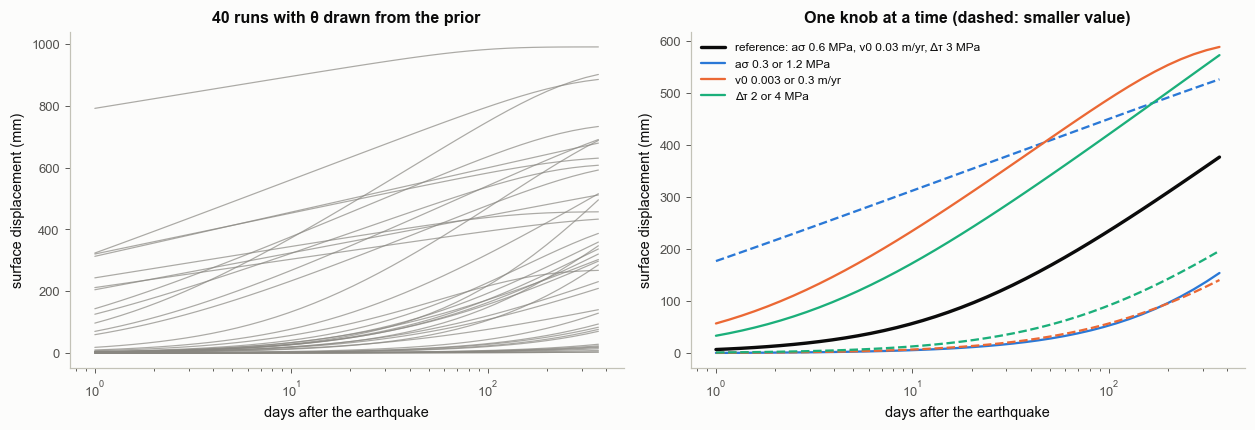

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.0))
ax = axs[0]
for k in rng.choice(len(TR), 40, replace=False):
    ax.plot(365.25 * T_OBS, U_all[k], color=S.MUTED, lw=0.8, alpha=0.7)
ax.set_xscale("log"); ax.set_xlabel("days after the earthquake"); ax.set_ylabel("surface displacement (mm)")
ax.set_title("40 runs with θ drawn from the prior")
ax = axs[1]
ax.plot(365.25 * T_OBS, u_knob[0], color=S.INK, lw=2.2, label="reference: aσ 0.6 MPa, v0 0.03 m/yr, Δτ 3 MPa")
j = 1
for i, vals, lab, col in knobs:
    for v, ls in zip(vals, ["--", "-"]):
        ax.plot(365.25 * T_OBS, u_knob[j], color=col, ls=ls, lw=1.5, label=lab if ls == "-" else None)
        j += 1
ax.set_xscale("log"); ax.set_xlabel("days after the earthquake"); ax.set_ylabel("surface displacement (mm)")
ax.set_title("One knob at a time (dashed: smaller value)")
ax.legend(fontsize=7.8, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "3-01_black_box")
plt.show()

**How to read it.** Left: the prior allows anything from almost no afterslip to the largest value printed above in the
first year, with curves that start early or late. Right: each parameter changes the curve in its own way. aσ sets
the slope on the log-time axis (and, through Δτ/aσ, when the rise starts), v0 shifts the curve sideways in time, and Δτ shifts it sideways and also sets where it
levels off (the patch cannot release more stress than it gained). A surrogate has to reproduce all of this to within
a fraction of 2 mm.

**Worked example: the bill.** Section 7 computes 150 synthetic posteriors on grids, at 4 × 90 × 90 forward
evaluations each, for 3 training-set sizes and 2 error models, plus a pipeline check with 400. The cell prints what
that would cost with the true model at the measured per-run cost, and how many runs the surrogates were trained on.

In [4]:
N_REP, NGRID, NLEV = 150, 90, 4
evals = (N_REP * 3 * 2 + 400) * NLEV * NGRID ** 2
print(f"forward evaluations in section 7: {evals:,}")
print(f"with the true model at {1e3 * t_batch:.2f} ms per run: {evals * t_batch / 3600:.1f} hours")
print(f"training runs used by the largest surrogate: {len(TR):,}, plus {len(VA)} validation runs  ->  "
      f"{(len(TR) + len(VA)) * t_batch:.0f} s of true-model time")
print("for a 3-D model at 1 hour per run, the same ratio of runs would be "
      f"{evals / 24 / 365:,.0f} years vs {len(TR) / 24:.0f} days")

forward evaluations in section 7: 42,120,000
with the true model at 2.86 ms per run: 33.4 hours
training runs used by the largest surrogate: 3,200, plus 400 validation runs  ->  10 s of true-model time
for a 3-D model at 1 hour per run, the same ratio of runs would be 4,808 years vs 133 days


**Common misreadings.**
* "A surrogate makes the forward model free." The training runs still cost full price; the surrogate moves that cost
  to before the inversion and spreads it over every evaluation afterwards.
* "Fast means accurate enough." Speed is easy; accuracy where the posterior lives is the hard part (sections 5-7).

**In practice.** Training runs are "embarrassingly parallel": no run depends on another, so they can all run at once
on a computing cluster, unlike the steps of an MCMC chain (2.16), each of which needs the previous one.

## 2. The workflow: design, run, fit, validate, use

**In plain words.** Building a surrogate has five steps, and the order matters. Choose where in parameter space to
run the model (design). Run it there (the expensive part). Fit a cheap function to the input-output pairs. Check it
on runs it has never seen (validate), in the units that matter for the inversion. Only then use it, and carry its
remaining error into the likelihood. If validation fails, go back and add runs where the error is large.

**Precisely.** Three disjoint sets of runs: **training** (the fit sees them), **validation** (used to choose settings
and to estimate the surrogate error, here for $\mathbf C_p$), **test** (used once, to grade). Grading on training
runs measures memory, not accuracy.

saved figures/3-01_workflow.png


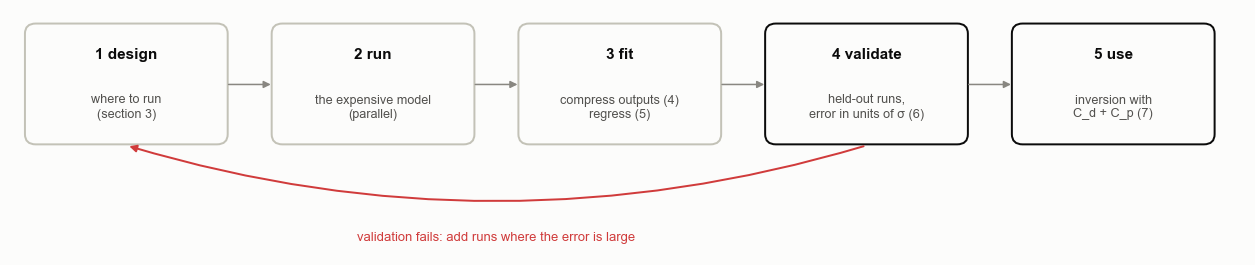

In [5]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(11.5, 2.5))
ax.set_xlim(0, 11.5); ax.set_ylim(-0.35, 2.05); ax.axis("off")
steps = [("1 design", "where to run\n(section 3)"), ("2 run", "the expensive model\n(parallel)"),
         ("3 fit", "compress outputs (4)\nregress (5)"), ("4 validate", "held-out runs,\nerror in units of σ (6)"),
         ("5 use", "inversion with\nC_d + C_p (7)")]
for k, (t, sub) in enumerate(steps):
    x = 0.15 + k * 2.3
    ax.add_patch(FancyBboxPatch((x, 0.75), 1.85, 1.15, boxstyle="round,pad=0.02,rounding_size=0.1", fc=S.SURFACE,
                                ec=S.INK if k in (3, 4) else S.AXIS, lw=1.3))
    ax.text(x + 0.925, 1.62, t, ha="center", va="center", fontsize=10, fontweight="bold")
    ax.text(x + 0.925, 1.1, sub, ha="center", va="center", fontsize=8.3, color=S.INK2)
    if k < 4:
        ax.annotate("", xy=(x + 2.3, 1.32), xytext=(x + 1.85, 1.32), arrowprops=dict(arrowstyle="-|>", color=S.MUTED))
ax.annotate("", xy=(0.15 + 0.925, 0.72), xytext=(0.15 + 3 * 2.3 + 0.925, 0.72),
            arrowprops=dict(arrowstyle="-|>", color=S.BAD, lw=1.3, connectionstyle="arc3,rad=-0.15"))
ax.text(0.15 + 1.5 * 2.3 + 0.925, -0.22, "validation fails: add runs where the error is large", ha="center",
        fontsize=8.5, color=S.BAD)
fig.tight_layout()
bk.savefig(fig, "3-01_workflow")
plt.show()

## 3. Where to run the model: the design

**In plain words.** With a budget of n runs, where should they go? Purely random points leave gaps and clumps by
chance. A **Latin hypercube** cuts each parameter's range into n equal slices and puts exactly one run in each slice
of each parameter, so every parameter is evenly covered on its own. A **Sobol sequence** is a deterministic recipe
that fills the box ever more evenly as points are added (a "quasi-random" or low-discrepancy sequence). All three are
space filling to some degree; they differ in how evenly.

**Precisely.** Random design: $x_i \sim U[0,1]^p$ independently. Latin hypercube (McKay, Beckman & Conover 1979):
$x_{ij} = (\pi_j(i) + u_{ij})/n$ with an independent random permutation $\pi_j$ of $0,\dots,n-1$ for each
parameter $j$ and $u_{ij}\sim U[0,1]$. Sobol (scrambled; scipy `qmc.Sobol`): a base-2 digital sequence, best used
with $n$ a power of 2. Evenness is measured by the **centred L2 discrepancy** (smaller is more even; scipy
`qmc.discrepancy`) and by the smallest distance between two design points (larger means no clumps).

**Worked example.** A 5-point Latin hypercube in 2-D, step by step: the permutations, then the points.

In [6]:
rw = np.random.default_rng(3)
n5 = 5
perm = np.stack([rw.permutation(n5) for _ in range(2)], 1)
jit_ = rw.uniform(size=(n5, 2))
x5 = (perm + jit_) / n5
for i in range(n5):
    print(f"point {i}: slice of parameter 1 = {perm[i, 0]}, slice of parameter 2 = {perm[i, 1]}, "
          f"jitter {np.round(jit_[i], 2)} -> x = {np.round(x5[i], 3)}")
print("each slice index 0..4 appears once per column:", sorted(perm[:, 0]), sorted(perm[:, 1]))

point 0: slice of parameter 1 = 4, slice of parameter 2 = 3, jitter [0.43 0.48] -> x = [0.887 0.696]
point 1: slice of parameter 1 = 2, slice of parameter 2 = 0, jitter [0.16 0.73] -> x = [0.432 0.147]
point 2: slice of parameter 1 = 1, slice of parameter 2 = 2, jitter [0.11 0.39] -> x = [0.223 0.478]
point 3: slice of parameter 1 = 3, slice of parameter 2 = 1, jitter [0.52 0.43] -> x = [0.703 0.286]
point 4: slice of parameter 1 = 0, slice of parameter 2 = 4, jitter [0.59 0.74] -> x = [0.117 0.948]
each slice index 0..4 appears once per column: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)] [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [7]:
def design(kind, n, seed):
    r = np.random.default_rng(seed)
    if kind == "random":
        return r.uniform(size=(n, 3))
    if kind == "Latin hypercube":
        return (np.stack([r.permutation(n) for _ in range(3)], 1) + r.uniform(size=(n, 3))) / n
    return qmc.Sobol(3, scramble=True, seed=seed).random(n)


def min_dist(X):
    d = np.sqrt(((X[:, None] - X[None]) ** 2).sum(-1)); d[np.diag_indices(len(X))] = np.inf
    return d.min()


KINDS = ["random", "Latin hypercube", "Sobol"]
KCOL = {"random": S.MUTED, "Latin hypercube": S.BLUE, "Sobol": S.ORANGE}
SEEDS_D = [11, 12, 13]
metrics = {k: {n: [(qmc.discrepancy(design(k, n, s)), min_dist(design(k, n, s))) for s in SEEDS_D] for n in (64, 256)}
           for k in KINDS}
for k in KINDS:
    for n in (64, 256):
        m = np.array(metrics[k][n])
        print(f"{k:16s} n={n:3d}: centred L2 discrepancy {m[:, 0].mean():.5f}, smallest distance {m[:, 1].mean():.4f}"
              f"   (mean of {len(SEEDS_D)} seeds)")

random           n= 64: centred L2 discrepancy 0.01172, smallest distance 0.0394   (mean of 3 seeds)
random           n=256: centred L2 discrepancy 0.00360, smallest distance 0.0235   (mean of 3 seeds)
Latin hypercube  n= 64: centred L2 discrepancy 0.00145, smallest distance 0.0623   (mean of 3 seeds)
Latin hypercube  n=256: centred L2 discrepancy 0.00039, smallest distance 0.0164   (mean of 3 seeds)
Sobol            n= 64: centred L2 discrepancy 0.00046, smallest distance 0.1140   (mean of 3 seeds)
Sobol            n=256: centred L2 discrepancy 0.00004, smallest distance 0.0462   (mean of 3 seeds)


Discrepancy is a property of the points alone. What matters for us is whether the design changes the accuracy of
the surrogate. We run the true model on each design (3 kinds × 2 sizes × 3 seeds, all new runs) and fit the same
surrogate (a Gaussian process; section 5 explains it) to each, then grade on the same 400 test runs.

In [8]:
# The PCA basis of all 3,200 training runs, shown in section 4 (which explains the compression). Each surrogate below
# builds its own basis from its own training runs (pca_basis), so its run count n is its whole training budget.
MU = U_all[TR].mean(0)
_, SV, VT = np.linalg.svd(U_all[TR] - MU, full_matrices=False)


def pca_basis(Uy, K):
    """Mean curve and the K leading modes of the outputs Uy (one row per run), computed from these runs only."""
    mu = Uy.mean(0)
    _, _, vt = np.linalg.svd(Uy - mu, full_matrices=False)
    return mu, vt[:K]


def k52(X1, X2, ell):
    """Matérn-5/2 kernel with one length scale per input (ARD), via squared distances."""
    a, b = X1 / ell, X2 / ell
    d2 = jnp.sum(a * a, 1)[:, None] + jnp.sum(b * b, 1)[None, :] - 2 * a @ b.T
    r = jnp.sqrt(5.0 * jnp.maximum(d2, 0.0) + 1e-24)
    return (1 + r + r * r / 3) * jnp.exp(-r)


def gp_nlml(lp, Xn, Zs):
    """Negative log marginal likelihood, summed over the K output coefficients (one shared kernel)."""
    ell, amp, nug = jnp.exp(lp[:3]), jnp.exp(2 * lp[3]), jnp.exp(2 * lp[4])
    Kx = amp * k52(Xn, Xn, ell) + (nug + 1e-10) * jnp.eye(Xn.shape[0])
    L = jnp.linalg.cholesky(Kx)
    a = jax.scipy.linalg.cho_solve((L, True), Zs)
    return 0.5 * jnp.sum(Zs * a) + Zs.shape[1] * jnp.sum(jnp.log(jnp.diag(L)))


def fit_gp(X, Uy, K, n_hyper=800):
    """GP surrogate on the K leading PCA coefficients. Hyperparameters by maximum marginal likelihood on at most
    n_hyper runs (two starting points), then the GP conditions on all runs. Returns a JAX function x (m, 3) -> u (m, 40) in mm."""
    mu, V = pca_basis(Uy, K)
    Z = (Uy - mu) @ V.T
    zm, zs = Z.mean(0), Z.std(0)
    Zs = (Z - zm) / zs
    nh = min(len(X), n_hyper)
    f = jax.jit(jax.value_and_grad(lambda p: gp_nlml(p, jnp.asarray(X[:nh]), jnp.asarray(Zs[:nh]))))
    res = [minimize(lambda p: [np.asarray(v, float) for v in f(jnp.asarray(p))], np.log(start), jac=True,
                    method="L-BFGS-B", bounds=[(-5, 2)] * 3 + [(-3, 3), (-12, 0)])
           for start in ([0.3, 0.3, 0.3, 1.0, 1e-2], [0.1, 0.1, 0.3, 1.0, 1e-4])]     # two starts, keep the better
    lp = min(res, key=lambda r: r.fun).x
    ell, amp, nug = np.exp(lp[:3]), np.exp(2 * lp[3]), np.exp(2 * lp[4])
    Kx = amp * np.asarray(k52(jnp.asarray(X), jnp.asarray(X), ell)) + (nug + 1e-10) * np.eye(len(X))
    alpha = np.linalg.solve(Kx, Zs)
    Xj, W, c, ellj = jnp.asarray(X), jnp.asarray(amp * (alpha * zs) @ V), jnp.asarray(zm @ V + mu), jnp.asarray(ell)

    def predict(x):
        return k52(x, Xj, ellj) @ W + c
    predict.hyper = dict(ell=ell, amp=amp, nugget=nug)
    return predict


def predict_np(f, X, chunk=4000):
    return np.concatenate([np.asarray(f(jnp.asarray(X[i:i + chunk]))) for i in range(0, len(X), chunk)])


K_PCA = 10                      # chosen in section 4 on the validation runs (checked there)
t0 = time.time()
des_err = {k: {n: [] for n in (64, 256)} for k in KINDS}
for k in KINDS:
    for n in (64, 256):
        for s in SEEDS_D:
            Xd = design(k, n, s)
            Ud = run_true(Xd)
            g = fit_gp(Xd, Ud, K_PCA)
            des_err[k][n].append(np.sqrt((rms_err(predict_np(g, Xte)) ** 2).mean()))
print(f"design study: {len(KINDS) * (64 + 256) * len(SEEDS_D)} new true-model runs and 18 GP fits in {time.time() - t0:.0f} s")
for k in KINDS:
    print(f"{k:16s} test RMS error (mm): n=64 {np.round(des_err[k][64], 1)}, n=256 {np.round(des_err[k][256], 1)}")

design study: 2880 new true-model runs and 18 GP fits in 14 s
random           test RMS error (mm): n=64 [112.1  84.3 102.8], n=256 [48.8 37.2 46. ]
Latin hypercube  test RMS error (mm): n=64 [ 90.8  78.  110. ], n=256 [43.3 55.4 36.7]
Sobol            test RMS error (mm): n=64 [71.5 57.3 76.7], n=256 [35.2 28.1 27.5]


saved figures/3-01_designs.png


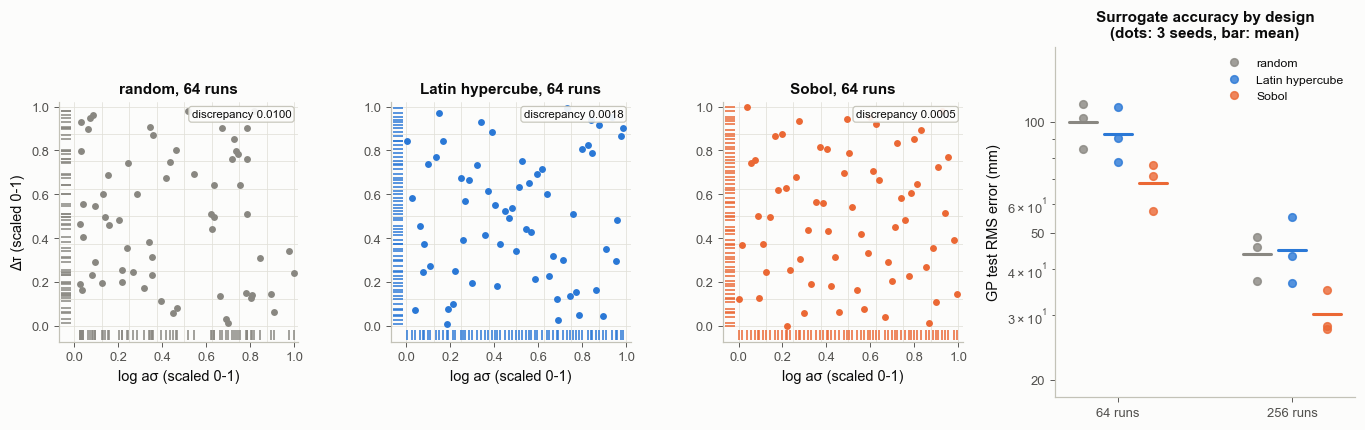

In [9]:
fig = plt.figure(figsize=(12.5, 4.0))
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 1.25])
for j, k in enumerate(KINDS):
    ax = fig.add_subplot(gs[0, j])
    Xd = design(k, 64, SEEDS_D[0])
    ax.plot(Xd[:, 0], Xd[:, 2], "o", ms=3.5, color=KCOL[k])
    ax.plot(Xd[:, 0], np.full(64, -0.04), "|", color=KCOL[k], ms=6)
    ax.plot(np.full(64, -0.04), Xd[:, 2], "_", color=KCOL[k], ms=6)
    for q in np.linspace(0, 1, 9):
        ax.axhline(q, color=S.GRID, lw=0.5, zorder=0); ax.axvline(q, color=S.GRID, lw=0.5, zorder=0)
    ax.set_xlim(-0.07, 1.02); ax.set_ylim(-0.07, 1.02); ax.set_aspect("equal")
    ax.set_xlabel("log aσ (scaled 0-1)"); ax.set_ylabel("Δτ (scaled 0-1)" if j == 0 else "")
    m = np.array(metrics[k][64])
    ax.set_title(f"{k}, 64 runs", fontsize=10)
    S.badge(ax, f"discrepancy {m[0, 0]:.4f}", loc="upper right", fs=7.5)
ax = fig.add_subplot(gs[0, 3])
for j, k in enumerate(KINDS):
    for i, n in enumerate((64, 256)):
        e = np.array(des_err[k][n])
        x = i + (j - 1) * 0.2
        ax.plot(np.full(len(e), x), e, "o", color=KCOL[k], ms=5, alpha=0.8, label=k if i == 0 else None)
        ax.plot([x - 0.08, x + 0.08], [e.mean()] * 2, color=KCOL[k], lw=2)
ax.set_xticks([0, 1]); ax.set_xticklabels(["64 runs", "256 runs"]); ax.set_yscale("log")
ax.set_yticks([20, 50, 100, 200]); ax.set_yticklabels(["20", "50", "100", "200"]); ax.set_ylim(18, 160)
ax.set_ylabel("GP test RMS error (mm)"); ax.set_title("Surrogate accuracy by design\n(dots: 3 seeds, bar: mean)",
                                                     fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
bk.savefig(fig, "3-01_designs")
plt.show()

**How to read it.** The three left panels show one 64-run design each, projected onto two of the three parameters
(ticks on the axes: the projections on one parameter). The Latin hypercube's ticks are evenly spaced along each
axis by construction; the random design has gaps and pairs. The right panel is what we care about: the test error of
the same surrogate trained on each design, for three seeds. Compare the spread between seeds of one design with the
differences between designs (printed above) before reading anything into the means. In this test every Sobol seed
beat the mean of the random designs at both sizes, while the three Latin hypercube seeds spread about as widely as the
gap between the designs. For every design, going from 64 to 256 runs lowered the error more than switching design
did.

**Common misreadings.**
* "A space-filling design is always better." In three dimensions with a few hundred runs the gain is modest compared
  with the run count; space filling matters more for small n and many parameters, and it never replaces putting runs
  where the posterior lives (section 7, and 3.03's sequential designs).
* "Sobol points are random." They are deterministic (scrambling adds a random shift); use powers of 2.

## 4. Compress the output: principal components

**In plain words.** One run gives 40 numbers (one per epoch), but they are far from independent: neighbouring epochs
move together, and every curve is a smooth rise. A handful of basic shapes, mixed in the right proportions, rebuild
every curve the model can make. The surrogate then only has to predict those few proportions instead of 40 numbers.

**Precisely.** Stack the centred training outputs as rows of a matrix and take its singular value decomposition,
$\mathbf U - \bar{\mathbf u} = \mathbf A\,\boldsymbol\Sigma\,\mathbf V^\top$. The rows of $\mathbf V^\top$ are the
**principal components** (modes); the coefficients of a curve are $\mathbf z = \mathbf V_K^\top(\mathbf u - \bar{\mathbf u})$
and the reconstruction is $\hat{\mathbf u} = \bar{\mathbf u} + \mathbf V_K\mathbf z$ with the first K modes. The
squared singular values say how much of the variation each mode carries (SVD: 2.06). We choose K on the
**validation** runs: the smallest K whose worst reconstruction error there is below 0.05 σ, so compression adds
nothing visible to the surrogate error. The test runs then grade the chosen K once.

In [10]:
Ks = np.arange(1, 21)
Uva = U_all[VA]


def reconstruction(Uq, K):
    V = VT[:K]
    R_ = (Uq - MU) - ((Uq - MU) @ V.T) @ V
    return np.sqrt((R_ ** 2).mean()), np.abs(R_).max()


rec_rms, rec_max = np.array([reconstruction(Uva, K) for K in Ks]).T
ok = rec_max < 0.05 * SIG
if not ok.any():                                  # argmax of an all-False array would silently return the first K
    raise RuntimeError("no K up to 20 reaches the 0.05 sigma rule; raise the largest K tried")
K_rule = int(Ks[np.argmax(ok)])
print(f"smallest K with worst VALIDATION reconstruction error < 0.05 sigma ({0.05 * SIG} mm): K = {K_rule}")
assert K_rule == K_PCA, "the K used in section 3 must match the rule"
te_rms, te_max = reconstruction(Ute, K_PCA)
print(f"graded once on the test runs: K = {K_PCA} reconstructs them with RMS {te_rms:.4f} mm, worst {te_max:.4f} mm")
energy = SV ** 2 / (SV ** 2).sum()
print("share of variance in modes 1-5:", np.round(energy[:5], 5), f"; modes 1-{K_PCA} together: {energy[:K_PCA].sum():.8f}")
for K in (1, 2, 3, 4, 6, K_PCA):
    print(f"K = {K:2d}: validation reconstruction RMS {rec_rms[K - 1]:.3f} mm, worst {rec_max[K - 1]:.3f} mm "
          f"({rec_max[K - 1] / SIG:.3f} sigma)")

smallest K with worst VALIDATION reconstruction error < 0.05 sigma (0.1 mm): K = 10
graded once on the test runs: K = 10 reconstructs them with RMS 0.0036 mm, worst 0.0424 mm
share of variance in modes 1-5: [9.458e-01 5.073e-02 3.230e-03 2.200e-04 2.000e-05] ; modes 1-10 together: 1.00000000
K =  1: validation reconstruction RMS 51.632 mm, worst 319.892 mm (159.946 sigma)
K =  2: validation reconstruction RMS 13.077 mm, worst 92.609 mm (46.304 sigma)
K =  3: validation reconstruction RMS 3.814 mm, worst 39.193 mm (19.596 sigma)
K =  4: validation reconstruction RMS 1.069 mm, worst 10.042 mm (5.021 sigma)
K =  6: validation reconstruction RMS 0.143 mm, worst 1.518 mm (0.759 sigma)
K = 10: validation reconstruction RMS 0.003 mm, worst 0.048 mm (0.024 sigma)


saved figures/3-01_pca.png


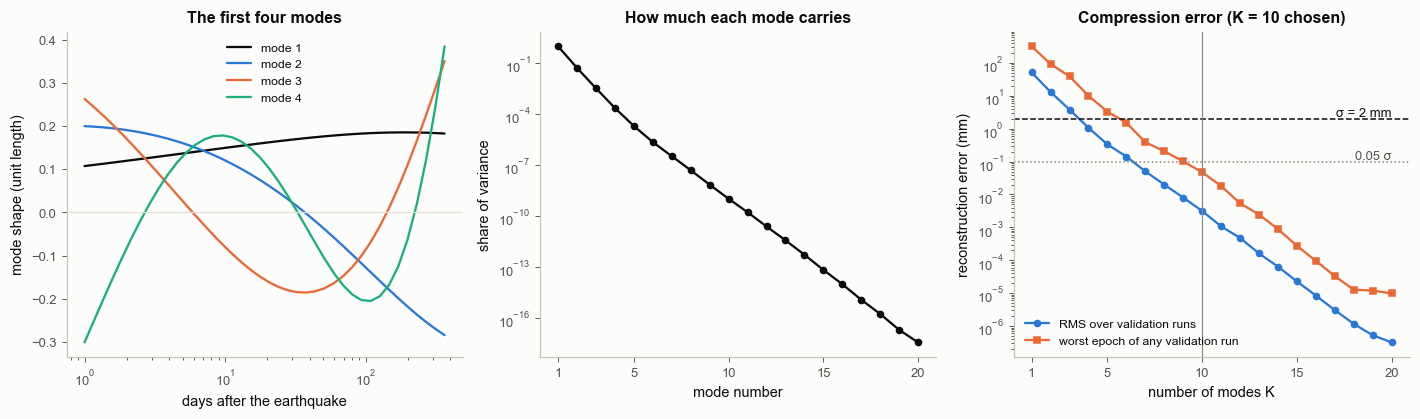

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(13.0, 3.9))
ax = axs[0]
for k, col in zip(range(4), [S.INK, S.BLUE, S.ORANGE, S.AQUA]):
    ax.plot(365.25 * T_OBS, VT[k], color=col, label=f"mode {k + 1}")
ax.axhline(0, color=S.GRID, lw=0.8)
ax.set_xscale("log"); ax.set_xlabel("days after the earthquake"); ax.set_ylabel("mode shape (unit length)")
ax.set_title("The first four modes"); ax.legend(fontsize=8)
ax = axs[1]
ax.semilogy(np.arange(1, 21), energy[:20], "o-", color=S.INK, ms=4)
ax.set_xlabel("mode number"); ax.set_ylabel("share of variance"); ax.set_title("How much each mode carries")
ax.set_xticks([1, 5, 10, 15, 20])
ax = axs[2]
ax.semilogy(Ks, rec_rms, "o-", color=S.BLUE, ms=4, label="RMS over validation runs")
ax.semilogy(Ks, rec_max, "s-", color=S.ORANGE, ms=4, label="worst epoch of any validation run")
ax.axhline(SIG, color=S.INK, lw=1, ls="--"); ax.text(20, SIG * 1.15, "σ = 2 mm", ha="right", fontsize=8.5)
ax.axhline(0.05 * SIG, color=S.MUTED, lw=1, ls=":"); ax.text(20, 0.05 * SIG * 1.15, "0.05 σ", ha="right", fontsize=8.5,
                                                              color=S.INK2)
ax.axvline(K_PCA, color=S.MUTED, lw=0.8)
ax.set_xlabel("number of modes K"); ax.set_ylabel("reconstruction error (mm)")
ax.set_title(f"Compression error (K = {K_PCA} chosen)"); ax.legend(fontsize=8, loc="lower left")
ax.set_xticks([1, 5, 10, 15, 20])
fig.tight_layout()
bk.savefig(fig, "3-01_pca")
plt.show()

**How to read it.** Left: mode 1 is roughly "more afterslip overall", the next modes shift where in time the curve
rises. Middle: the share of variance falls by orders of magnitude from mode to mode. Right: the error of rebuilding the
400 validation curves from K modes, against the 2 mm noise. Past the chosen K the compression error is far below the noise,
so whatever error the surrogates make below is regression error, not compression error.

**Worked example.** Rebuild one test curve from 1, 2, 3 and K modes (coefficients and errors printed).

In [12]:
i0 = TE[7]
z0 = (U_all[i0] - MU) @ VT[:K_PCA].T
print(f"test run {i0}: theta = {np.round(th_all[i0], 3)}, year-1 displacement {U_all[i0, -1]:.1f} mm")
print("coefficients z_1..z_K:", np.round(z0, 2))
for K in (1, 2, 3, K_PCA):
    rec = MU + z0[:K] @ VT[:K]
    print(f"  K = {K:2d}: worst epoch error {np.abs(rec - U_all[i0]).max():8.3f} mm")

test run 3607: theta = [-0.973 -0.055  1.608], year-1 displacement 321.6 mm
coefficients z_1..z_K: [ 1.7964e+02  3.7170e+01 -1.9498e+02  6.3500e+00  1.2060e+01  3.7600e+00
  2.2000e+00 -1.7400e+00  4.1000e-01 -1.6000e-01]
  K =  1: worst epoch error   71.774 mm
  K =  2: worst epoch error   61.214 mm
  K =  3: worst epoch error    7.119 mm
  K = 10: worst epoch error    0.010 mm


**Common misreadings.**
* "PCA keeps the important physics." It keeps the directions of largest variation over the *training design*. A
  feature that is small in amplitude but decisive for one parameter can sit in a late mode; check reconstruction
  error in units of σ, not the share of variance.
* "K modes means K parameters." K is the size of the output summary; the number of unknowns is still 3.

## 5. Five surrogates, one test set: learning curves

**In plain words.** Any method that turns input-output examples into a function can serve as a surrogate. We try
five, from rigid to flexible, and train each on the first n training runs for n from 50 to 3,200. Each fit, including
its PCA basis, uses only those n runs, so n is the whole training budget; the K = 10 chosen on the validation runs is
kept for every n. The **learning
curve** (test error against n) shows how each one improves as it sees more runs. A rigid method stops improving early
(its shape cannot follow the model); a flexible one keeps improving but needs more runs to get going.

**Precisely.** All five map the scaled inputs $x\in[0,1]^3$ to the K PCA coefficients, and the prediction is
rebuilt to 40 epochs in mm.

| surrogate | what it is | fitting |
|---|---|---|
| linear | $\mathbf z \approx \mathbf a + \mathbf B x$ | least squares |
| quadratic | all terms up to $x_i x_j$ (10 per coefficient) | least squares |
| k-nearest neighbours | distance-weighted mean of the 5 closest training runs | none (stores the runs) |
| Gaussian process | conditional mean of a GP with a Matérn-5/2 kernel, one length scale per input, shared by the K coefficients (notebook 2.12) | hyperparameters by maximum marginal likelihood (two starting points) on at most 800 runs, then conditioned on all n |
| neural network (3.02) | 3 hidden layers of 64 tanh units | Adam, 4,000 full-batch steps, cosine-decaying step size 0.003 |

Three of these need a word here. **k-nearest neighbours** predicts at a new point from the stored runs closest to it,
weighting nearer ones more. A **neural network** is a function built from layers: each layer takes weighted sums of
its inputs and passes them through a simple bend (here tanh, an S-shaped curve), and the weights are fitted by
minimising a loss with a gradient method (Adam, 2.10); 3.02 builds one line by line. "Cosine-decaying step size"
means the optimiser's step shrinks smoothly from 0.003 to zero along a half cosine wave over the run. The **Gaussian
process** (2.12) predicts with the conditional mean of a GP prior given the runs; its kernel settings (length scales,
amplitude and a small "nugget" variance on the diagonal, which keeps the matrix well conditioned) are its
hyperparameters, chosen by maximising the marginal likelihood (the evidence, 2.29).

The error at each test point is the RMS over the 40 epochs; every test point is a possible true θ, so the spread
of this error over the test set is the spread of errors an inversion could meet.

In [13]:
def poly_feats(X, deg):
    cols = [np.ones(len(X))] + [X[:, i] for i in range(3)]
    if deg >= 2:
        cols += [X[:, i] * X[:, j] for i in range(3) for j in range(i, 3)]
    return np.stack(cols, 1)


def fit_poly(X, Uy, deg, K=K_PCA):
    mu, V = pca_basis(Uy, K)
    c = np.linalg.lstsq(poly_feats(X, deg), (Uy - mu) @ V.T, rcond=None)[0]
    return lambda Xq: poly_feats(np.asarray(Xq), deg) @ c @ V + mu


def fit_knn(X, Uy, K=K_PCA):
    mu, V = pca_basis(Uy, K)
    m = KNeighborsRegressor(5, weights="distance").fit(X, (Uy - mu) @ V.T)
    return lambda Xq: m.predict(np.asarray(Xq)) @ V + mu


# --- a small neural network with Adam written out (3.02 explains every line)
def mlp_init(key, sizes):
    ps = []
    for a, b in zip(sizes[:-1], sizes[1:]):
        key, k = jax.random.split(key)
        ps.append((jax.random.normal(k, (a, b)) * np.sqrt(1.0 / a), jnp.zeros(b)))
    return ps


def mlp(ps, x):
    for W, b in ps[:-1]:
        x = jnp.tanh(x @ W + b)
    W, b = ps[-1]
    return x @ W + b


def adam_train(loss, ps, n_steps, lr0):
    """Adam (Kingma & Ba 2015) with a cosine-decaying step size; returns trained parameters and the loss history."""
    def step(carry, i):
        ps, m, v = carry
        l, g = jax.value_and_grad(loss)(ps)
        lr, t = lr0 * 0.5 * (1 + jnp.cos(jnp.pi * i / n_steps)), i + 1.0
        m = jax.tree.map(lambda a, b: 0.9 * a + 0.1 * b, m, g)
        v = jax.tree.map(lambda a, b: 0.999 * a + 0.001 * b * b, v, g)
        ps = jax.tree.map(lambda p, a, b: p - lr * (a / (1 - 0.9 ** t)) / (jnp.sqrt(b / (1 - 0.999 ** t)) + 1e-8), ps, m, v)
        return (ps, m, v), l
    zeros = jax.tree.map(jnp.zeros_like, ps)
    (ps, _, _), hist = jax.lax.scan(step, (ps, zeros, zeros), jnp.arange(n_steps, dtype=jnp.float64))
    return ps, hist


def fit_mlp(X, Uy, K=K_PCA, n_steps=4000, seed=0):
    mu, V = pca_basis(Uy, K)
    Z = (Uy - mu) @ V.T
    zm, zs = Z.mean(0), Z.std(0)
    Xj, Zj = jnp.asarray(X), jnp.asarray((Z - zm) / zs)
    loss = lambda ps: jnp.mean((mlp(ps, Xj) - Zj) ** 2)
    ps, hist = jax.jit(lambda p: adam_train(loss, p, n_steps, 3e-3))(mlp_init(jax.random.PRNGKey(seed), [3, 64, 64, 64, K]))
    Vj, zsj, cj = jnp.asarray(V), jnp.asarray(zs), jnp.asarray(zm @ V + mu)

    def predict(x):
        return (mlp(ps, x) * zsj) @ Vj + cj
    predict.final_loss = float(hist[-1])
    return predict


METHODS = {"linear": (lambda X, Uy: fit_poly(X, Uy, 1), S.AXIS),
           "quadratic": (lambda X, Uy: fit_poly(X, Uy, 2), S.MUTED),
           "k-nearest neighbours": (fit_knn, S.AQUA),
           "Gaussian process": (lambda X, Uy: fit_gp(X, Uy, K_PCA), S.BLUE),
           "neural network": (fit_mlp, S.ORANGE)}
NS = [50, 100, 200, 400, 800, 1600, 3200]
lc = {m: {} for m in METHODS}
surr, tr_err = {}, {}
t_fit = {m: 0.0 for m in METHODS}
for m, (fit, _) in METHODS.items():
    for n in NS:
        t0 = time.time()
        f = fit(X_all[TR[:n]], U_all[TR[:n]])
        t_fit[m] += time.time() - t0
        pred = predict_np(f, Xte) if m in ("Gaussian process", "neural network") else f(Xte)
        lc[m][n] = rms_err(pred)
        surr[(m, n)] = f
        if m == "neural network":
            tr_err[n] = np.sqrt((rms_err(predict_np(f, X_all[TR[:n]]), U_all[TR[:n]]) ** 2).mean())
for m in METHODS:
    print(f"{m:21s} test RMS error (mm) by n: " + "  ".join(f"{np.sqrt((lc[m][n] ** 2).mean()):7.2f}" for n in NS)
          + f"   [fitting time, all n: {t_fit[m]:.1f} s]")
print("n:" + " " * 42 + "  ".join(f"{n:7d}" for n in NS))
for m in ("Gaussian process", "neural network"):
    print(f"{m:21s} median error: " + "  ".join(f"{np.median(lc[m][n]):6.2f}" for n in NS)
          + f";  share of test points within sigma: " + " ".join(f"{(lc[m][n] < SIG).mean():.2f}" for n in NS))
print("neural network RMS error on its own training runs (mm): " + "  ".join(f"{tr_err[n]:.2f}" for n in NS))
print("compression alone (the n-run PCA basis, K = %d), worst validation reconstruction error (mm): " % K_PCA
      + "  ".join(f"{np.abs((Uva - mu_) - ((Uva - mu_) @ V_.T) @ V_).max():.3f}"
                  for mu_, V_ in (pca_basis(U_all[TR[:n]], K_PCA) for n in NS)))
g8 = surr[("Gaussian process", 800)]
print("GP hyperparameters at n = 800 (scaled inputs): length scales", np.round(g8.hyper["ell"], 3),
      f"amplitude {g8.hyper['amp']:.2f}, nugget {g8.hyper['nugget']:.1e}")
# evaluation cost of the two fast surrogates (batch of 4000 points, per point)
for m in ("Gaussian process", "neural network"):
    f = jax.jit(surr[(m, 3200)])
    f(jnp.asarray(Xte[:400])).block_until_ready()
    xb = jnp.asarray(np.random.default_rng(1).uniform(size=(4000, 3)))
    f(xb).block_until_ready(); t0 = time.time(); f(xb).block_until_ready()
    print(f"{m} (n = 3200) evaluation: {1e6 * (time.time() - t0) / 4000:.1f} microseconds per point "
          f"(true model {1e3 * t_batch:.2f} ms per run)")

linear                test RMS error (mm) by n:  110.81   110.63   109.72   108.80   108.39   108.17   108.05   [fitting time, all n: 0.0 s]
quadratic             test RMS error (mm) by n:   53.08    49.31    48.02    47.36    46.92    46.90    46.77   [fitting time, all n: 0.0 s]
k-nearest neighbours  test RMS error (mm) by n:   53.95    44.89    36.27    30.17    24.37    18.81    14.98   [fitting time, all n: 0.0 s]
Gaussian process      test RMS error (mm) by n:   91.15    66.97    46.07    23.72    10.02     5.69     1.50   [fitting time, all n: 5.6 s]
neural network        test RMS error (mm) by n:   40.35    23.10    13.95     7.90     4.66     4.68     4.03   [fitting time, all n: 20.9 s]
n:                                               50      100      200      400      800     1600     3200
Gaussian process      median error:  39.54   19.95   11.05    4.20    1.57    0.42    0.16;  share of test points within sigma: 0.01 0.03 0.09 0.31 0.56 0.80 0.93
neural network        med

neural network (n = 3200) evaluation: 0.2 microseconds per point (true model 2.86 ms per run)


saved figures/3-01_learning_curves.png


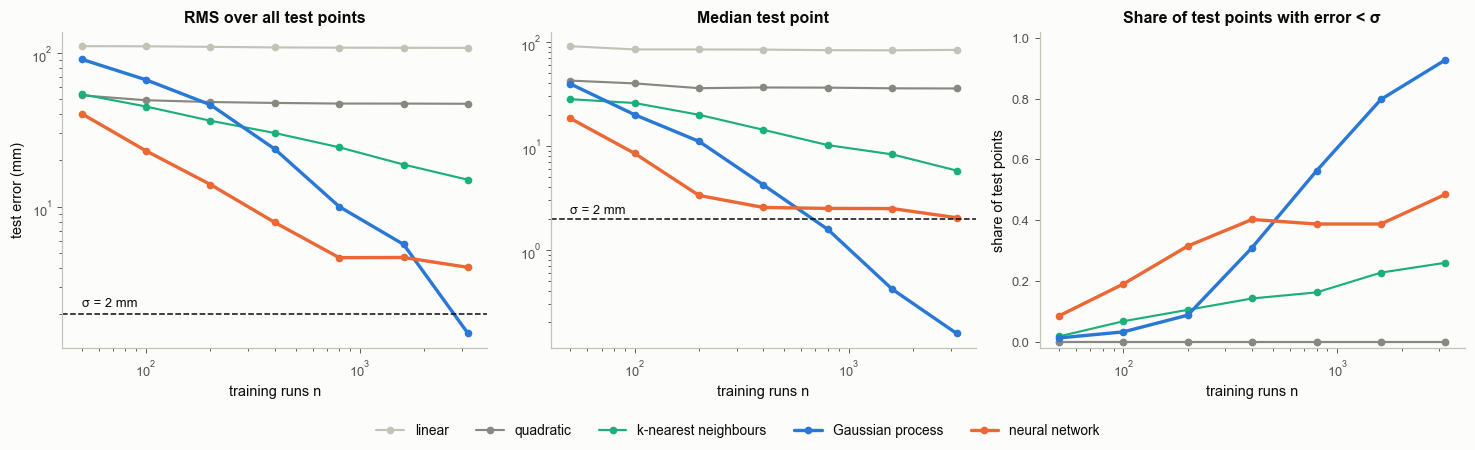

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(13.5, 4.1))
for m, (_, col) in METHODS.items():
    r = [np.sqrt((lc[m][n] ** 2).mean()) for n in NS]
    md = [np.median(lc[m][n]) for n in NS]
    fr = [(lc[m][n] < SIG).mean() for n in NS]
    lw = 2.2 if m in ("Gaussian process", "neural network") else 1.4
    axs[0].loglog(NS, r, "o-", color=col, lw=lw, ms=4, label=m)
    axs[1].loglog(NS, md, "o-", color=col, lw=lw, ms=4)
    axs[2].semilogx(NS, fr, "o-", color=col, lw=lw, ms=4)
for ax in axs[:2]:
    ax.axhline(SIG, color=S.INK, ls="--", lw=1); ax.text(NS[0], SIG * 1.12, "σ = 2 mm", fontsize=8.5)
    ax.set_xlabel("training runs n")
axs[0].set_ylabel("test error (mm)"); axs[0].set_title("RMS over all test points")
axs[1].set_title("Median test point")
axs[2].set_ylim(-0.02, 1.02); axs[2].set_xlabel("training runs n"); axs[2].set_ylabel("share of test points")
axs[2].set_title("Share of test points with error < σ")
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.legend(*axs[0].get_legend_handles_labels(), loc="lower center", ncol=5, fontsize=9)
bk.savefig(fig, "3-01_learning_curves")
plt.show()

**How to read it.** Each line is one surrogate; the dashed line is the GPS noise. Left and middle: the RMS is pulled
up by the worst test points, the median shows the typical one; the gap between the two panels is a first sign that
the errors are very uneven (section 6). The linear and quadratic fits flatten early: more runs cannot fix a shape that
is too rigid: its error is **bias**, a systematic misfit that does not shrink with more data. k-nearest neighbours keeps improving, but slowly, because the distance to the nearest training
run shrinks only like $n^{-1/3}$ in three dimensions. Only the Gaussian process and the neural network bring the
typical (median) error down to the noise level or below, and only the GP takes its RMS below σ, at the largest n. The
network stops improving after a few hundred runs; from 800 runs on, its error on its own training runs (printed) is
about as large as its test error, so with this fixed training budget it is limited by training, not by data (3.02
trains it better).
Right: the share of possible true θ where the surrogate is within σ; the rest are places where an inversion with this
surrogate would be fitting the surrogate's error. The compression part of these errors is negligible at every n: each
n-run PCA basis rebuilds the validation runs to within the printed worst errors, all below 0.05 σ (0.1 mm).

**Common misreadings.**
* "Pick the surrogate with the lowest RMS." The RMS mixes a typical error with a few large ones; the inversion meets
  one θ at a time, so look at the whole distribution (right panel and section 6).
* "The neural network lost to the GP, so networks are worse." This network got a fixed, small training budget;
  3.02 shows how much training choices matter. Compare methods at equal care, and say what each got.

## 6. Where the surrogate is wrong: error maps and extrapolation

**In plain words.** A surrogate's error is not spread evenly. It is largest where the model changes fastest and where
training runs are sparse, typically at the edges and corners of the design box. Outside the box it has no information
at all, and each method falls back on its own built-in habit: a polynomial keeps curving, a GP returns to its mean, a
network continues whatever its last layer was doing.

**Precisely.** Interpolation = predicting inside the convex hull of the training inputs (the smallest region with
flat faces that encloses all of them); extrapolation = outside.
Below, (a) maps the GP's test error (n = 800) over the parameters, and (b) trains three surrogates only on the
training runs with Δτ ≤ 4 MPa (count printed) and grades them on all test runs, binned by Δτ.

In [15]:
e8 = lc["Gaussian process"][800]
th_te = th_all[TE]
ratio = th_te[:, 2] / np.exp(th_te[:, 0])                     # dtau / a_sigma: how far the stress jump is above a_sigma
q = np.quantile(e8, [0.5, 0.9])
hi_ = e8 > q[1]
print(f"GP n = 800: median test error {q[0]:.2f} mm, 90th percentile {q[1]:.2f} mm, worst {e8.max():.1f} mm")
print(f"Δτ/aσ: median over all test points {np.median(ratio):.1f}; over the worst 10 % {np.median(ratio[hi_]):.1f}")
print(f"distance of the worst 10 % to the nearest box face (scaled units): median "
      f"{np.median(np.minimum(Xte[hi_], 1 - Xte[hi_]).min(1)):.3f} vs all test points "
      f"{np.median(np.minimum(Xte, 1 - Xte).min(1)):.3f}")

# extrapolation experiment
cut = 4.0
inside = th_all[TR, 2] <= cut
Xin, Uin = X_all[TR][inside], U_all[TR][inside]
ext = {}
for m in ("quadratic", "Gaussian process", "neural network"):
    f = METHODS[m][0](Xin, Uin)
    pred = predict_np(f, Xte) if m != "quadratic" else f(Xte)
    ext[m] = rms_err(pred)
bins = np.linspace(1, 5, 9)
bc = 0.5 * (bins[1:] + bins[:-1])
print(f"extrapolation test: trained on {inside.sum()} runs with Δτ <= {cut} MPa")
for m, e in ext.items():
    med = [np.median(e[(th_te[:, 2] >= a) & (th_te[:, 2] < b)]) for a, b in zip(bins[:-1], bins[1:])]
    print(f"  {m:17s} median error by Δτ bin (mm): " + " ".join(f"{v:7.1f}" for v in med))

GP n = 800: median test error 1.57 mm, 90th percentile 11.00 mm, worst 68.4 mm
Δτ/aσ: median over all test points 4.0; over the worst 10 % 5.4
distance of the worst 10 % to the nearest box face (scaled units): median 0.026 vs all test points 0.093


extrapolation test: trained on 2420 runs with Δτ <= 4.0 MPa
  quadratic         median error by Δτ bin (mm):    25.7    18.8    23.4    31.1    39.2    47.9    55.9    65.8
  Gaussian process  median error by Δτ bin (mm):     0.3     0.0     0.0     0.1     0.2     0.5    17.3   116.7
  neural network    median error by Δτ bin (mm):     1.8     0.8     1.2     1.2     1.3     2.3     6.1    14.7


saved figures/3-01_error_maps.png


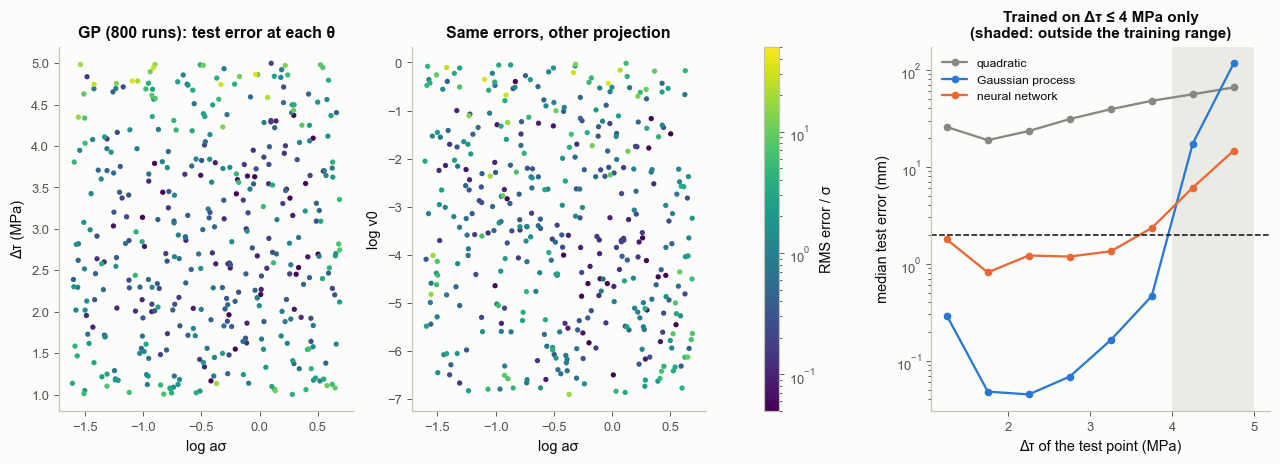

In [16]:
fig = plt.figure(figsize=(14.2, 4.3))
gsm = fig.add_gridspec(1, 5, width_ratios=[1, 1, 0.05, 0.12, 1.15], wspace=0.3)
axs = [fig.add_subplot(gsm[0, i]) for i in (0, 1, 4)]
cax = fig.add_subplot(gsm[0, 2])
from matplotlib.colors import LogNorm
norm = LogNorm(0.05, 50)
for ax, (i, j) in zip(axs[:2], [(0, 2), (0, 1)]):
    o = np.argsort(e8)
    sc = ax.scatter(th_te[o, i], th_te[o, j], c=e8[o] / SIG, cmap="viridis", norm=norm, s=12, lw=0)
    ax.set_xlabel(NAMES[i]); ax.set_ylabel(NAMES[j])
axs[0].set_title("GP (800 runs): test error at each θ")
axs[1].set_title("Same errors, other projection")
cb = fig.colorbar(sc, cax=cax); cb.set_label("RMS error / σ")
ax = axs[2]
for m, col in [("quadratic", S.MUTED), ("Gaussian process", S.BLUE), ("neural network", S.ORANGE)]:
    med = [np.median(ext[m][(th_te[:, 2] >= a) & (th_te[:, 2] < b)]) for a, b in zip(bins[:-1], bins[1:])]
    ax.semilogy(bc, med, "o-", color=col, label=m, ms=4)
ax.axvspan(cut, 5, color=S.GRID, alpha=0.6, lw=0)
ax.axhline(SIG, color=S.INK, ls="--", lw=1)
ax.set_xlabel("Δτ of the test point (MPa)"); ax.set_ylabel("median test error (mm)")
ax.set_title(f"Trained on Δτ ≤ {cut:.0f} MPa only\n(shaded: outside the training range)", fontsize=10)
ax.legend(fontsize=8, loc="upper left")
bk.savefig(fig, "3-01_error_maps")
plt.show()

**How to read it.** Left and middle: each dot is a test θ, coloured by the GP's error in units of σ (yellow = large).
Read off where the large errors sit, and compare with the printed numbers: how Δτ/aσ and the distance to the box
faces differ between the worst 10 % and all test points. Right: trained on Δτ ≤ 4 MPa, each surrogate is graded on
test runs across the full range; inside the training range (white) the errors are those of the learning curves, in
the shaded range there were no training runs. There the GP's error grows fastest (away from its runs it falls back
towards its mean), the network degrades more gently in this case, and the quadratic is poor everywhere.

**Worked example: how big an error matters.** Take one test point, keep Δτ known (as in section 7), and compute the
shift in (log aσ, log v0) that the surrogate error alone would cause in a least-squares fit, in units of the posterior
standard deviation: to first order $\delta\theta = (\mathbf J^\top\mathbf J)^{-1}\mathbf J^\top\mathbf e$ with the surrogate's Jacobian
$\mathbf J$ (40 × 2: how much each epoch's prediction changes per unit change of each parameter; Jacobian, 2.10)
and error vector $\mathbf e$; this is the least-squares formula of 2.07 applied to the error. The posterior standard deviations are
$\sigma\sqrt{\operatorname{diag}(\mathbf J^\top\mathbf J)^{-1}}$.

In [17]:
f8 = surr[("Gaussian process", 800)]
order = np.argsort(e8)
for label, i_ex in [("median", int(order[len(e8) // 2])), ("90th percentile", int(order[int(0.9 * len(e8))]))]:
    x_ex = Xte[i_ex]
    e_vec = Ute[i_ex] - np.asarray(f8(jnp.asarray(x_ex[None])))[0]
    J = np.asarray(jax.jacfwd(lambda x2: f8(jnp.concatenate([x2, jnp.asarray(x_ex[2:])])[None])[0])(jnp.asarray(x_ex[:2])))
    J = J / (HI[:2] - LO[:2])                                     # per unit of log aσ and log v0
    JtJi = np.linalg.inv(J.T @ J)
    shift = JtJi @ J.T @ e_vec
    sd = SIG * np.sqrt(np.diag(JtJi))
    print(f"test point with the {label} error: RMS error {e8[i_ex]:.2f} mm = {e8[i_ex] / SIG:.2f} sigma;"
          f" |e|^2 / sigma^2 = {(e_vec ** 2).sum() / SIG ** 2:.1f}")
    print(f"    shift in (log aσ, log v0): {np.round(shift, 4)}; posterior sd {np.round(sd, 4)};"
          f" shift / sd = {np.round(shift / sd, 2)}")

test point with the median error: RMS error 1.57 mm = 0.79 sigma; |e|^2 / sigma^2 = 24.8
    shift in (log aσ, log v0): [-0.0511 -0.0698]; posterior sd [0.0114 0.0602]; shift / sd = [-4.48 -1.16]
test point with the 90th percentile error: RMS error 11.05 mm = 5.52 sigma; |e|^2 / sigma^2 = 1220.3
    shift in (log aσ, log v0): [-0.1048 -0.2262]; posterior sd [0.0032 0.0101]; shift / sd = [-32.36 -22.29]


Even a sub-σ error per epoch adds up over 40 epochs, and the part of it that looks like a parameter change moves
the estimate by a number of posterior standard deviations (printed). That is the bridge to the next section: the
surrogate error must be judged against the posterior width, not against the size of the signal.

**Common misreadings.**
* "1 % relative error is good." Here 1 % of a 500 mm signal is 2.5 σ per epoch.
* "Test error averaged over the prior box is the accuracy." The posterior occupies a tiny part of the box; what
  matters is the error there (Lu, Morzfeld, Tu & Chorin 2014, quoted in section 8).

## 7. Surrogate error is model error: $\mathbf C_p$ and coverage

**In plain words.** If we invert real data with a surrogate, the data and the surrogate disagree for two reasons: the
GPS noise, and the surrogate's own error. Treating the second as if it were zero is exactly the mistake of 2.13
(ignoring model error), and it has the same symptom: a posterior that is too narrow and in the wrong place. The cure
is also the same: estimate how large the surrogate error typically is, from runs the surrogate was not trained on,
and add it to the noise covariance.

**Precisely.** The data are $\mathbf d = \mathbf f(\theta) + \mathbf e$ with the true model $\mathbf f$. With a
surrogate $\hat{\mathbf f}$,

$$\mathbf d = \hat{\mathbf f}(\theta) + \underbrace{[\mathbf f(\theta) - \hat{\mathbf f}(\theta)]}_{\text{surrogate error}} + \mathbf e,
\qquad \mathbf C_\chi = \mathbf C_d + \mathbf C_p,\qquad
\mathbf C_p \approx \frac{1}{N_v}\sum_{i\in\text{validation}} \mathbf r_i\mathbf r_i^\top,\ \ \mathbf r_i = \mathbf f(\theta_i) - \hat{\mathbf f}(\theta_i).$$

This $\mathbf C_p$ is one covariance for the whole prior box (a global estimate); errors that vary from place to
place (section 6) are averaged. 3.03 replaces it with the GP's own predictive variance, which is local.

**The experiment.** 150 repeats per row (400 for the pipeline check); in each, the true θ is one of the test runs (so it is drawn from the prior), the
data are the *true model's* output plus new noise, Δτ is known, and the posterior of (log aσ, log v0) is computed
exactly for the surrogate on grids (90 × 90 points over the prior box, then three 90 × 90 grids laid along the
posterior's principal axes, each spanning ±7 standard deviations of the previous one). As in 2.01, we count how
often the true value lies inside the 50 % and 90 % regions: the true value is inside the q region when the posterior
mass at points denser than the true value is at most q. Three rows:
1. **pipeline check**: data made by the surrogate itself, inverted with the surrogate and $\mathbf C_d$. The
   surrogate is then the exact model, so the counts must match 50 % and 90 %; this checks the grid machinery;
2. **true-model data, $\mathbf C_d$ only**;
3. **true-model data, $\mathbf C_d + \mathbf C_p$** with $\mathbf C_p$ from the 400 validation runs.

In [18]:
def rotated_grid(m, Cw, ng, W=7.0):
    """ng x ng grid spanning +-W standard deviations along the principal axes of the covariance Cw around m."""
    lam, R = np.linalg.eigh(Cw)
    B = R * np.sqrt(np.maximum(lam, 1e-30))
    u = np.linspace(-W, W, ng)
    G = m + np.stack(np.meshgrid(u, u, indexing="ij"), -1).reshape(-1, 2) @ B.T
    step = B * (u[1] - u[0])
    return G, abs(np.linalg.det(step)), step @ step.T


def grid_moments(G, p, step_cov):
    m = p @ G
    return m, ((G - m) * p[:, None]).T @ (G - m) + step_cov       # + one cell, so a one-cell posterior still has width


def make_posterior(f, C, nlev=NLEV, ng=NGRID):
    """Exact surrogate posterior of (log aσ, log v0) for known dtau, uniform prior on the box: a regular grid over the
    box, then nlev - 1 grids along the posterior's principal axes (+-7 sd), each from the previous one's moments."""
    Ci = jnp.asarray(np.linalg.inv(C))

    @jax.jit
    def loglik(x01, d, x2):
        x = jnp.concatenate([jnp.clip(x01, 0, 1), jnp.full((x01.shape[0], 1), x2)], 1)
        r = d[None, :] - f(x)
        inside = jnp.all((x01 >= 0) & (x01 <= 1), 1)
        return jnp.where(inside, -0.5 * jnp.sum((r @ Ci) * r, 1), -jnp.inf)

    g = np.linspace(0, 1, ng)
    G0 = np.stack(np.meshgrid(g, g, indexing="ij"), -1).reshape(-1, 2)
    h = g[1] - g[0]

    def post(d, x_true):
        d, x2 = jnp.asarray(d), float(x_true[2])
        G, cell, step_cov = G0, h * h, np.diag([h * h, h * h])
        for lev in range(nlev):
            if lev > 0:
                G, cell, step_cov = rotated_grid(*grid_moments(G, p, step_cov), ng)
            lp = np.asarray(loglik(jnp.asarray(G), d, x2))
            p = np.exp(lp - lp.max()); p /= p.sum()
        P2 = p.reshape(ng, ng)
        edge = P2[0].sum() + P2[-1].sum() + P2[:, 0].sum() + P2[:, -1].sum()   # mass on the window border (zero outside the box)
        ps = np.sort(p)[::-1]; cs = np.cumsum(ps)
        n50 = int(np.searchsorted(cs, 0.5) + 1)
        lt = float(loglik(jnp.asarray(x_true[None, :2]), d, x2)[0])
        frac = p[lp > lt].sum()                                    # posterior mass denser than the true value
        area90 = (np.searchsorted(cs, 0.9) + 1) * cell * np.prod(HI[:2] - LO[:2])
        return dict(frac=frac, n50=n50, edge=edge, area90=area90, G=G, P2=P2, moments=grid_moments(G, p, step_cov))
    return post


def coverage_run(f, C, data_from, n_rep=N_REP, seed=7):
    post = make_posterior(f, C)
    r = np.random.default_rng(seed)
    out = []
    for j in range(n_rep):
        i = TE[j]
        clean = U_all[i] if data_from == "true" else predict_np(f, X_all[i:i + 1])[0]
        out.append(post(clean + SIG * r.standard_normal(40), X_all[i]))
    fr = np.array([o["frac"] for o in out])
    return dict(c50=(fr <= 0.5).mean(), c90=(fr <= 0.9).mean(), out=out, n_rep=n_rep,
                n50=min(o["n50"] for o in out), edge=max(o["edge"] for o in out),
                area=np.median([o["area90"] for o in out]))


Cd = SIG ** 2 * np.eye(40)
cov_res = {}
Cp_of = {}
t0 = time.time()
for n in (200, 800, 3200):
    f = surr[("Gaussian process", n)]
    rv = U_all[VA] - predict_np(f, X_all[VA])
    Cp_of[n] = rv.T @ rv / len(VA)
    rows = [("true", "Cd", Cd, N_REP), ("true", "Cd+Cp", Cd + Cp_of[n], N_REP)]
    if n == 800:
        rows = [("surrogate", "Cd", Cd, len(TE))] + rows          # the pipeline check uses all 400 test runs
    for src, lab, C, nr in rows:
        cov_res[(n, src, lab)] = coverage_run(f, C, src, n_rep=nr)
print(f"coverage experiment: {time.time() - t0:.0f} s")
def se2(q_, nr):
    return 2 * np.sqrt(q_ * (1 - q_) / nr)                       # 2 standard errors of a count of nr yes/no outcomes


for (n, src, lab), r_ in cov_res.items():
    print(f"n = {n:4d}, data from {src:9s}, {lab:6s} ({r_['n_rep']} repeats): inside 50 % region {r_['c50']:.3f}, inside 90 % region "
          f"{r_['c90']:.3f};  median area of 90 % region {r_['area']:.2e} (log aσ × log v0);"
          f"  fewest cells holding 50 %: {r_['n50']}, largest truncated mass {r_['edge']:.1e}")
for (n, src, lab), r_ in cov_res.items():                       # grid check: repeats the grids resolve poorly
    bad = np.array([(o["edge"] > 1e-2) or (o["n50"] < 10) for o in r_["out"]])
    fr_ = np.array([o["frac"] for o in r_["out"]])[~bad]
    print(f"n = {n:4d}, {src:9s}, {lab:6s}: {bad.sum():2d} repeats with > 1 % of the probability on the window border or"
          f" < 10 cells holding 50 %; without them: inside 50 % {np.mean(fr_ <= 0.5):.3f}, inside 90 % {np.mean(fr_ <= 0.9):.3f}")
for nr in (N_REP, len(TE)):
    print(f"expected scatter from {nr} repeats (2 standard errors): 50 %: ±{se2(0.5, nr):.3f}, 90 %: ±{se2(0.9, nr):.3f}")
print(f"area of the prior box in (log aσ, log v0): {np.prod(HI[:2] - LO[:2]):.1f}")
for n in (200, 800, 3200):
    print(f"n = {n:4d}: median 90 % area with C_d + C_p / with C_d only = "
          f"{cov_res[(n, 'true', 'Cd+Cp')]['area'] / cov_res[(n, 'true', 'Cd')]['area']:.1f}")
for n in (200, 800, 3200):
    print(f"n = {n:4d}: sqrt(mean diagonal of C_p) = {np.sqrt(np.diag(Cp_of[n]).mean()):.2f} mm  "
          f"(noise sigma {SIG} mm)")

coverage experiment: 56 s
n =  200, data from true     , Cd     (150 repeats): inside 50 % region 0.013, inside 90 % region 0.033;  median area of 90 % region 4.40e-04 (log aσ × log v0);  fewest cells holding 50 %: 6, largest truncated mass 3.6e-04
n =  200, data from true     , Cd+Cp  (150 repeats): inside 50 % region 0.533, inside 90 % region 0.787;  median area of 90 % region 3.34e-01 (log aσ × log v0);  fewest cells holding 50 %: 38, largest truncated mass 3.2e-04
n =  800, data from surrogate, Cd     (400 repeats): inside 50 % region 0.480, inside 90 % region 0.897;  median area of 90 % region 8.10e-04 (log aσ × log v0);  fewest cells holding 50 %: 2, largest truncated mass 2.3e-01
n =  800, data from true     , Cd     (150 repeats): inside 50 % region 0.133, inside 90 % region 0.307;  median area of 90 % region 8.22e-04 (log aσ × log v0);  fewest cells holding 50 %: 5, largest truncated mass 8.5e-03
n =  800, data from true     , Cd+Cp  (150 repeats): inside 50 % region 0.680, in

saved figures/3-01_coverage.png


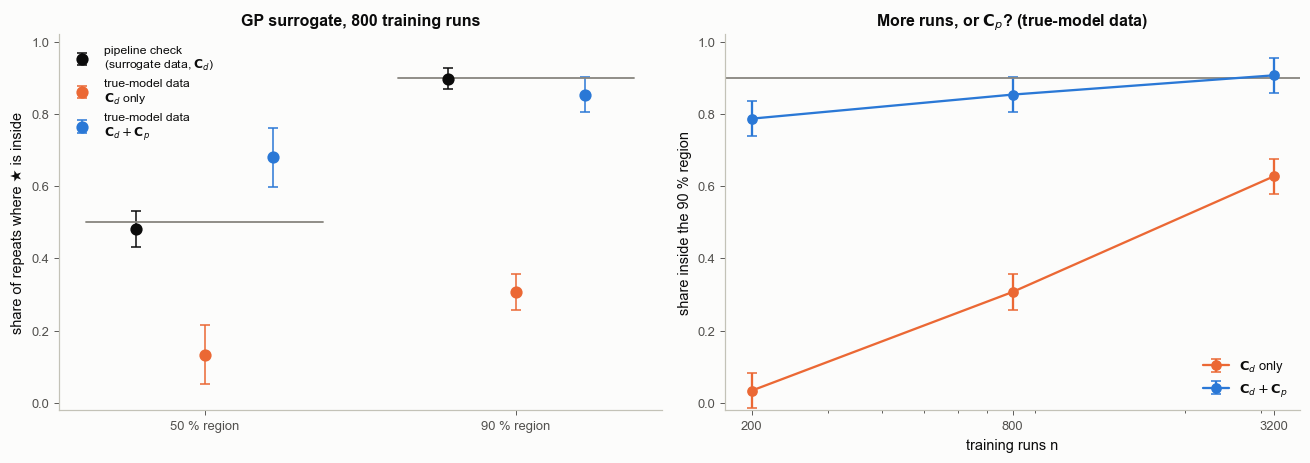

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(12.0, 4.3), gridspec_kw=dict(width_ratios=[1.05, 1]))
ax = axs[0]
rows = [((800, "surrogate", "Cd"), "pipeline check\n(surrogate data, $\\mathbf{C}_d$)", S.INK),
        ((800, "true", "Cd"), "true-model data\n$\\mathbf{C}_d$ only", S.ORANGE),
        ((800, "true", "Cd+Cp"), "true-model data\n$\\mathbf{C}_d + \\mathbf{C}_p$", S.BLUE)]
for k, (key, lab, col) in enumerate(rows):
    for i, q_ in enumerate((0.5, 0.9)):
        v = cov_res[key]["c50" if q_ == 0.5 else "c90"]
        x = i + (k - 1) * 0.22
        ax.errorbar(x, v, yerr=se2(q_, cov_res[key]["n_rep"]), fmt="o", color=col, ms=7, capsize=3, lw=1, label=lab if i == 0 else None)
for i, q_ in enumerate((0.5, 0.9)):
    ax.plot([i - 0.38, i + 0.38], [q_, q_], color=S.MUTED, lw=1.2)
ax.set_xticks([0, 1]); ax.set_xticklabels(["50 % region", "90 % region"]); ax.set_ylim(-0.02, 1.02)
ax.set_ylabel("share of repeats where ★ is inside"); ax.set_title("GP surrogate, 800 training runs")
ax.legend(fontsize=8, loc="upper left")
ax = axs[1]
for lab, col in [("Cd", S.ORANGE), ("Cd+Cp", S.BLUE)]:
    c90 = [cov_res[(n, "true", lab)]["c90"] for n in (200, 800, 3200)]
    ax.errorbar([200, 800, 3200], c90, yerr=se2(0.9, N_REP), fmt="o-", color=col, capsize=3, ms=6,
                label="$\\mathbf{C}_d$ only" if lab == "Cd" else "$\\mathbf{C}_d + \\mathbf{C}_p$")
ax.axhline(0.9, color=S.MUTED, lw=1.2)
ax.set_xscale("log"); ax.set_xticks([200, 800, 3200]); ax.set_xticklabels(["200", "800", "3200"])
ax.set_ylim(-0.02, 1.02); ax.set_xlabel("training runs n"); ax.set_ylabel("share inside the 90 % region")
ax.set_title("More runs, or $\\mathbf{C}_p$? (true-model data)"); ax.legend(fontsize=8.5, loc="lower right")
fig.tight_layout()
bk.savefig(fig, "3-01_coverage")
plt.show()

**How to read it.** Left: grey lines are the promise (50 % and 90 %), bars are ±2 standard errors from the finite
number of repeats (narrower for the 400-repeat pipeline check). The last two numbers on each printed line check the
grids: the largest probability on a grid border bounds what the window cut off, and the fewest cells holding half the
probability flags the few posteriors that are long, bent ridges or pieces pressed against the edge of the prior box.
A few repeats fail one of these checks (counted on the next printed lines, with the counts recomputed without them);
leaving them out moves the counts by little compared with the scatter expected from the number of repeats. The black
pipeline check sits on the promise, so the machinery is right and anything else is the surrogate's doing. With true-model data and $\mathbf C_d$ only (orange) the regions miss the true value far more often than
promised. Adding $\mathbf C_p$ (blue) brings the counts much closer to the promise, but not exactly onto it: one
global $\mathbf C_p$ is too wide where the surrogate is good, so the 50 % region catches the true value more often
than half the time, and too narrow where it is bad, so the 90 % region catches it a little less often than promised
(printed above). Right: the 90 % count against the number of training runs. More runs shrink the surrogate error
and raise the $\mathbf C_d$-only count, but even with the largest training set it stays well below the promise;
with $\mathbf C_p$ the count approaches the promise as n grows. The price is width: the 90 % regions with
$\mathbf C_p$ are larger than those with $\mathbf C_d$ only by the printed factors, and the factor falls as the
surrogate improves.

One of the repeats, drawn in full: the true model's own exact posterior (computed on a grid with true-model runs,
affordable for one data set), and the two surrogate posteriors for the same data.

repeats where the C_d-only 90 % region misses the true value and the C_d + C_p one catches it: 82 of 150


candidates tried until the true model's own 90 % region contains the true value: 2 (12100 true-model runs, 5 s)
chosen repeat 3: true-model posterior mass denser than the true value 0.41; surrogate C_d only 1.000, surrogate C_d + C_p 0.24; probability on the true-model grid border 2.0e-07
saved figures/3-01_example_posterior.png


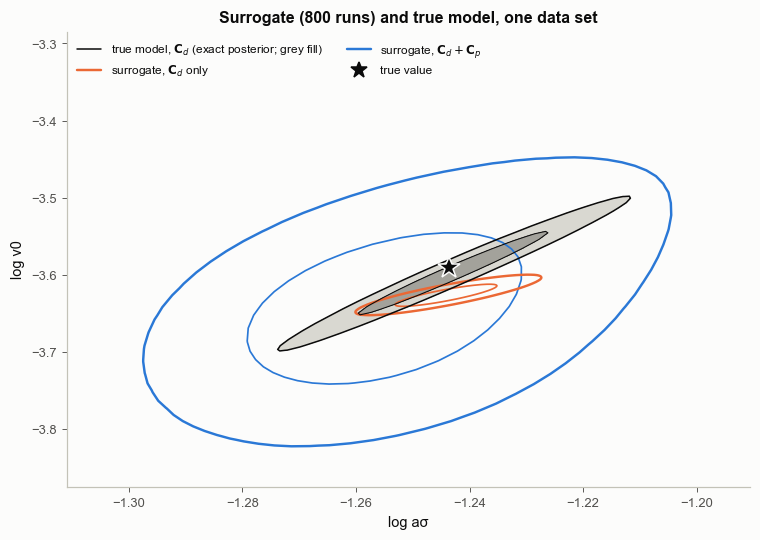

In [20]:
res_cd, res_cp = cov_res[(800, "true", "Cd")]["out"], cov_res[(800, "true", "Cd+Cp")]["out"]
cands = [j for j in range(N_REP) if res_cd[j]["frac"] > 0.9 and res_cp[j]["frac"] <= 0.9]
print(f"repeats where the C_d-only 90 % region misses the true value and the C_d + C_p one catches it: "
      f"{len(cands)} of {N_REP}")
def true_posterior(d, x_true, m, Cw, ng=55, nlev=2, W=5.0):
    """Exact posterior with the true model: rotated grids of ng x ng true-model runs, starting from moments (m, Cw)."""
    lt = -0.5 * ((d - run_true(x_true[None])[0]) ** 2).sum() / SIG ** 2
    for lev in range(nlev):
        G, cell, step_cov = rotated_grid(m, Cw, ng, W)
        inside = np.all((G >= 0) & (G <= 1), 1)
        lp = np.full(len(G), -np.inf)
        ut = run_true(np.c_[G[inside], np.full(inside.sum(), x_true[2])])
        lp[inside] = -0.5 * ((d[None] - ut) ** 2).sum(1) / SIG ** 2
        p = np.exp(lp - lp.max()); p /= p.sum()
        m, Cw = grid_moments(G, p, step_cov)
    P2 = p.reshape(ng, ng)
    return dict(G=G, P2=P2, frac=p[lp > lt].sum(), edge=P2[0].sum() + P2[-1].sum() + P2[:, 0].sum() + P2[:, -1].sum(),
                runs=nlev * ng * ng)


t0 = time.time()
for tried, j_ex in enumerate(cands, 1):
    r = np.random.default_rng(7)                                   # replay the data of coverage_run
    for j in range(j_ex + 1):
        d_ex = U_all[TE[j]] + SIG * r.standard_normal(40)
    x_true = X_all[TE[j_ex]]
    tp = true_posterior(d_ex, x_true, *res_cp[j_ex]["moments"])
    if tp["frac"] <= 0.9:
        break
print(f"candidates tried until the true model's own 90 % region contains the true value: {tried} "
      f"({tried * tp['runs']} true-model runs, {time.time() - t0:.0f} s)")
print(f"chosen repeat {j_ex}: true-model posterior mass denser than the true value {tp['frac']:.2f}; "
      f"surrogate C_d only {res_cd[j_ex]['frac']:.3f}, surrogate C_d + C_p {res_cp[j_ex]['frac']:.2f}; "
      f"probability on the true-model grid border {tp['edge']:.1e}")


def hdr_contour(ax, G, P2, col, lw=1.6, fill=False):
    """50 % and 90 % regions of a gridded posterior (curvilinear grid), drawn in (log aσ, log v0)."""
    ps = np.sort(P2.ravel())[::-1]; cs = np.cumsum(ps)
    levs = [ps[np.searchsorted(cs, q_)] for q_ in (0.9, 0.5)]
    ng = P2.shape[0]
    X0 = (LO[0] + G[:, 0] * (HI[0] - LO[0])).reshape(ng, ng)
    X1 = (LO[1] + G[:, 1] * (HI[1] - LO[1])).reshape(ng, ng)
    if fill:
        ax.contourf(X0, X1, P2, levels=[levs[0], levs[1], P2.max() * 1.01], colors=["#d9d8d1", "#a3a29b"])
    ax.contour(X0, X1, P2, levels=levs, colors=[col, col], linewidths=[lw, lw * 0.7])
    return X0[P2 >= levs[0]], X1[P2 >= levs[0]]


fig, ax = plt.subplots(figsize=(7.0, 5.0))
th_true = to_theta(x_true)
bx, by = hdr_contour(ax, res_cp[j_ex]["G"], res_cp[j_ex]["P2"], S.BLUE)
hdr_contour(ax, res_cd[j_ex]["G"], res_cd[j_ex]["P2"], S.ORANGE)
hdr_contour(ax, tp["G"], tp["P2"], S.INK, fill=True, lw=1.0)
ax.plot(th_true[0], th_true[1], "*", color=S.INK, ms=15, mec=S.SURFACE, zorder=5)
ax.set_xlabel("log aσ"); ax.set_ylabel("log v0")
ax.set_xlim(bx.min() - 0.15 * np.ptp(bx), bx.max() + 0.15 * np.ptp(bx))
ax.set_ylim(by.min() - 0.15 * np.ptp(by), by.max() + 0.45 * np.ptp(by))
ax.set_title("Surrogate (800 runs) and true model, one data set")
from matplotlib.lines import Line2D
h = [Line2D([], [], color=S.INK, lw=1.0, label="true model, $\\mathbf{C}_d$ (exact posterior; grey fill)"),
     Line2D([], [], color=S.ORANGE, lw=1.6, label="surrogate, $\\mathbf{C}_d$ only"),
     Line2D([], [], color=S.BLUE, lw=1.6, label="surrogate, $\\mathbf{C}_d + \\mathbf{C}_p$"),
     Line2D([], [], color=S.INK, marker="*", ls="", ms=11, label="true value")]
ax.legend(handles=h, fontsize=7.8, loc="upper left", ncol=2)
fig.tight_layout()
bk.savefig(fig, "3-01_example_posterior")
plt.show()

**How to read it.** Thick lines: 90 % regions; thin lines: 50 % regions. The grey filled region is the answer we
would get with the expensive model; it is what the surrogate posteriors should reproduce. The orange region (surrogate,
noise only) is about as small as the grey one but shifted, and it misses the true value: the surrogate error moved it,
and it is as confident as if the surrogate were exact. The blue region (with $\mathbf C_p$) is much larger and contains both the
grey region and the true value. This repeat was picked as the first one in which the orange region misses, the blue
one catches, and the true model's own region catches (how often the first two happen together, and how many repeats
were tried, are printed above); it illustrates the counts and is not extra evidence.

**Common misreadings.**
* "Adding $\mathbf C_p$ fixes the surrogate." It makes the posterior honest about the surrogate's error, by widening
  it. The information lost to the surrogate error is not recovered; only more or better training runs do that.
* "One global $\mathbf C_p$ is right everywhere." It is the average error over the prior box: too large where the
  surrogate is good (the posterior is wider than needed) and too small where it is bad. Local error estimates (GP
  variance, 3.03) and runs added near the posterior (sequential design, 3.03) do better.

## 8. Summary

| step | what to do | what goes wrong otherwise |
|---|---|---|
| design | space-filling design over the prior; add runs where the posterior lives | gaps, and accuracy spent where the posterior never goes |
| compress | PCA of the outputs, K from the reconstruction error in units of σ | a surrogate for 40 correlated numbers, or lost signal |
| fit | try a flexible method (GP, network) and a simple baseline | a rigid fit that cannot improve with more runs |
| validate | held-out runs, error per test point in units of σ, maps of where it is large | an average error that hides the bad corners |
| use | $\mathbf C_\chi = \mathbf C_d + \mathbf C_p$, check coverage on synthetic tests | confident, wrong posteriors |

Lu, Morzfeld, Tu & Chorin (2014, abstract, p. 1), on polynomial-chaos surrogates (polynomials in the parameters,
built to be accurate on average over the prior), state the general version:
"when the data contain significant information beyond what is assumed in the prior, the surrogate posterior can be
very different from the posterior, and the resulting estimates become inaccurate." In section 7 the data are far
more informative than the prior box, and that is exactly what the $\mathbf C_d$-only rows show.

**In practice.** Calibrate-emulate-sample (3.03) is this recipe with two changes: the training runs are placed near
the posterior by a cheap first inversion, and the GP's own predictive variance replaces the single global
$\mathbf C_p$. Whatever the surrogate, the two checks of this notebook carry over: learning curves answer "how many
runs" for accuracy in units of the noise, and coverage on synthetic tests answers it for the posterior.

Next: [**3.02 · Neural networks and ResNets from scratch**](3-02_neural_networks_resnets.ipynb).

In [21]:
print(f"notebook run time: {time.time() - T0:.0f} s")

notebook run time: 118 s
